# 4.1.2-Plotting of markers

**Inés Sentís**

Explore variability within samples

Date of execution

In [1]:
Sys.Date()

[1] "2026-03-26"

## Libraries

In [2]:
suppressMessages(suppressWarnings({
library(Seurat)
library(Signac)
library(tidyverse)
library(ComplexHeatmap)
library(edgeR)
library(here)
library(glue)
}))

## Parameters

In [3]:
#here::dr_here(show_reason = TRUE)
source(here("utils/bin.R"))
source(here("utils/paths.R"))
source(here("AVGUSTINOVA_02_to_30/utils/style.R"))

set.seed(0)

In [4]:
scaling=FALSE

## Load Data

In [5]:
combined_obj <- readRDS(here(glue("{int}/{robj_dir}/4.1.0-tumor_fraction.rds")))

In [6]:
markers <- c(
    # --- 1. Tyrosine Kinase Signalling and Growth Factors ---
    'BMP5', 'EREG', 'FGF5', 'HGF', 'NRG1', 'NRG3', 'PDGFD', 'TGFB2', # Growth Factors/Ligands
     'EPHA3','EPHA5', 'EPHA6', 'ERBB4', 'FGFR1', 'FGFR2', 'MET', # Receptor Tyrosine Kinases (RTKs)

    # --- 2. Cell Adhesion and ECM (Extracellular Matrix) ---
    'ADGRL3', 'CDH2', # Adhesion/Receptors
    'LAMA1', 'LAMA4', 'MMP9', 'POSTN', 'SMOC2', # ECM Components/Regulators

    # --- 3. Transcription Factors ---
    'FOXP2', 'MITF', 'MEOX2', 'POU6F2', 'SOX5', 'SOX6', # Transcription Factors

    # --- 4. Developmental Related and Oncofetal Genes ---
    'ROBO1', 'ROBO2', 'SEMA3D', 'SEMA3E', 'SEMA5A', 'SEMA6D', 'UNC5D', # Guidance/Receptors
    'GPC3', 'GPC5', 'GPC6', 'LGR5', 'OTX2-AS1', # Stem/Developmental Markers

    # --- 5. Others ---
    'KCNQ5', 'KCNT2', # Ion Channels
    'ALDH1A1', 'TYR', # Metabolism/Enzyme
    'CFH', 'ERVMER61-1', 'GPM6A', 'MGP', 'SGCZ', 'SHROOM3' # Regulatory/Structural
)

In [7]:
combined_obj <- SetIdent(combined_obj, value=combined_obj@meta.data$patient)

In [8]:
# create pseudobulks per ident and normalise as logCPM
list_objects <- SplitObject(combined_obj, split.by = "ident")
list_objects <- list_objects[match(levels(combined_obj), names(list_objects))]
col_names <-  names(list_objects)

counts <- matrix(nrow=dim(list_objects[[1]]@assays$RNA@counts)[1], ncol=0)
lib_sizes <- c()

for (d in col_names){
  obj <- list_objects[[d]]

  m <- as.matrix(obj@assays$RNA@counts)
  c <- rowSums(m)
  counts <- cbind(counts, c)

  ls <- sum(colSums(m))
  lib_sizes <- c(lib_sizes, ls)
}
colnames(counts)<-col_names

# manual computation
logCPM <- counts
for (i in seq_along(names(list_objects))){
  ls <- lib_sizes[i]
  d <- colnames(logCPM)[i]
  logCPM[, d]<-log2((logCPM[, d]/ls*1e6)+1) 
} 

Warning message in asMethod(object):
“sparse->dense coercion: allocating vector of size 2.6 GiB”
Warning message in asMethod(object):
“sparse->dense coercion: allocating vector of size 2.8 GiB”
Warning message in asMethod(object):
“sparse->dense coercion: allocating vector of size 1.3 GiB”
Warning message in asMethod(object):
“sparse->dense coercion: allocating vector of size 2.6 GiB”
Warning message in asMethod(object):
“sparse->dense coercion: allocating vector of size 1.2 GiB”
Warning message in asMethod(object):
“sparse->dense coercion: allocating vector of size 1.3 GiB”
Warning message in asMethod(object):
“sparse->dense coercion: allocating vector of size 1.1 GiB”
Warning message in asMethod(object):
“sparse->dense coercion: allocating vector of size 2.7 GiB”


In [9]:
# compute pecentatge of cells expressing each gene
percent_expression <- matrix(nrow = nrow(list_objects[[1]]@assays$RNA@counts), ncol = 0)

for (d in col_names) {
  obj <- list_objects[[d]]

  m <- as.matrix(obj@assays$RNA@counts)
  percent_expr <- rowMeans(m > 0) * 100  # Calculate the percentage of cells with non-zero expression
  percent_expression <- cbind(percent_expression, percent_expr)
}

colnames(percent_expression) <- col_names
rownames(percent_expression) <- rownames(list_objects[[1]]@assays$RNA@counts)

# transform the data

if (scaling == T) {
    # scaling as z-scoring 
    mat1 <- t(scale(t(logCPM)))
    mat1 <- mat1[unlist(markers, use.names = F),]

    # aesthetics for the dotplot
    pal_gradient = RColorBrewer::brewer.pal(n = 11, name = "RdYlBu")
    leg_name =  "z-score\nnorm. expr."
} else {
    mat1 <- logCPM[unlist(markers, use.names = F),]
    pal_gradient = RColorBrewer::brewer.pal(n = 11, name = "YlOrRd")
    leg_name = "norm. expr."
}

# from matrix to df for ggplot2
expression_df <- as.data.frame(mat1) %>%
rownames_to_column(var = "Gene")

expression_df <- expression_df %>%
    pivot_longer(
        cols = -Gene, 
        names_to = "Patient",  
        values_to = "Expression")

percent_expression_df <- as.data.frame(percent_expression) %>%
  rownames_to_column(var = "Gene") %>%
  pivot_longer(
    cols = -Gene,
    names_to = "Patient",
    values_to = "PercentExpressing"
  )
expression_df <- left_join(expression_df, percent_expression_df, by = c("Gene", "Patient"))

# set order
expression_df[["Patient"]] <- factor(expression_df[["Patient"]],
                                              levels=rev(col_names))

expression_df[["Gene"]] <- factor(expression_df[["Gene"]],
                                          levels=unlist(markers, use.names = F))

Warning message in asMethod(object):
“sparse->dense coercion: allocating vector of size 2.6 GiB”
Warning message in asMethod(object):
“sparse->dense coercion: allocating vector of size 2.8 GiB”
Warning message in asMethod(object):
“sparse->dense coercion: allocating vector of size 1.3 GiB”
Warning message in asMethod(object):
“sparse->dense coercion: allocating vector of size 2.6 GiB”
Warning message in asMethod(object):
“sparse->dense coercion: allocating vector of size 1.2 GiB”
Warning message in asMethod(object):
“sparse->dense coercion: allocating vector of size 1.3 GiB”
Warning message in asMethod(object):
“sparse->dense coercion: allocating vector of size 1.1 GiB”
Warning message in asMethod(object):
“sparse->dense coercion: allocating vector of size 2.7 GiB”
Warning message in RColorBrewer::brewer.pal(n = 11, name = "YlOrRd"):
“n too large, allowed maximum for palette YlOrRd is 9
Returning the palette you asked for with that many colors
”


In [10]:
custom_order <- c('p2','p8','p14','p17','p13','p9','p7','p6','p15','p10','p16','p3','p5','p1','p4','p19')
expression_df$Patient <- factor(expression_df$Patient, levels = custom_order)

In [11]:
head(expression_df)

Gene,Patient,Expression,PercentExpressing
<fct>,<fct>,<dbl>,<dbl>
BMP5,p2,4.725931,3.034085
BMP5,p8,5.383012,3.929899
BMP5,p14,1.411724,0.341783
BMP5,p17,7.348419,12.978454
BMP5,p13,10.030656,89.330581
BMP5,p9,9.413691,56.642171


Warning message:
“Removed 22 rows containing missing values (`geom_point()`).”


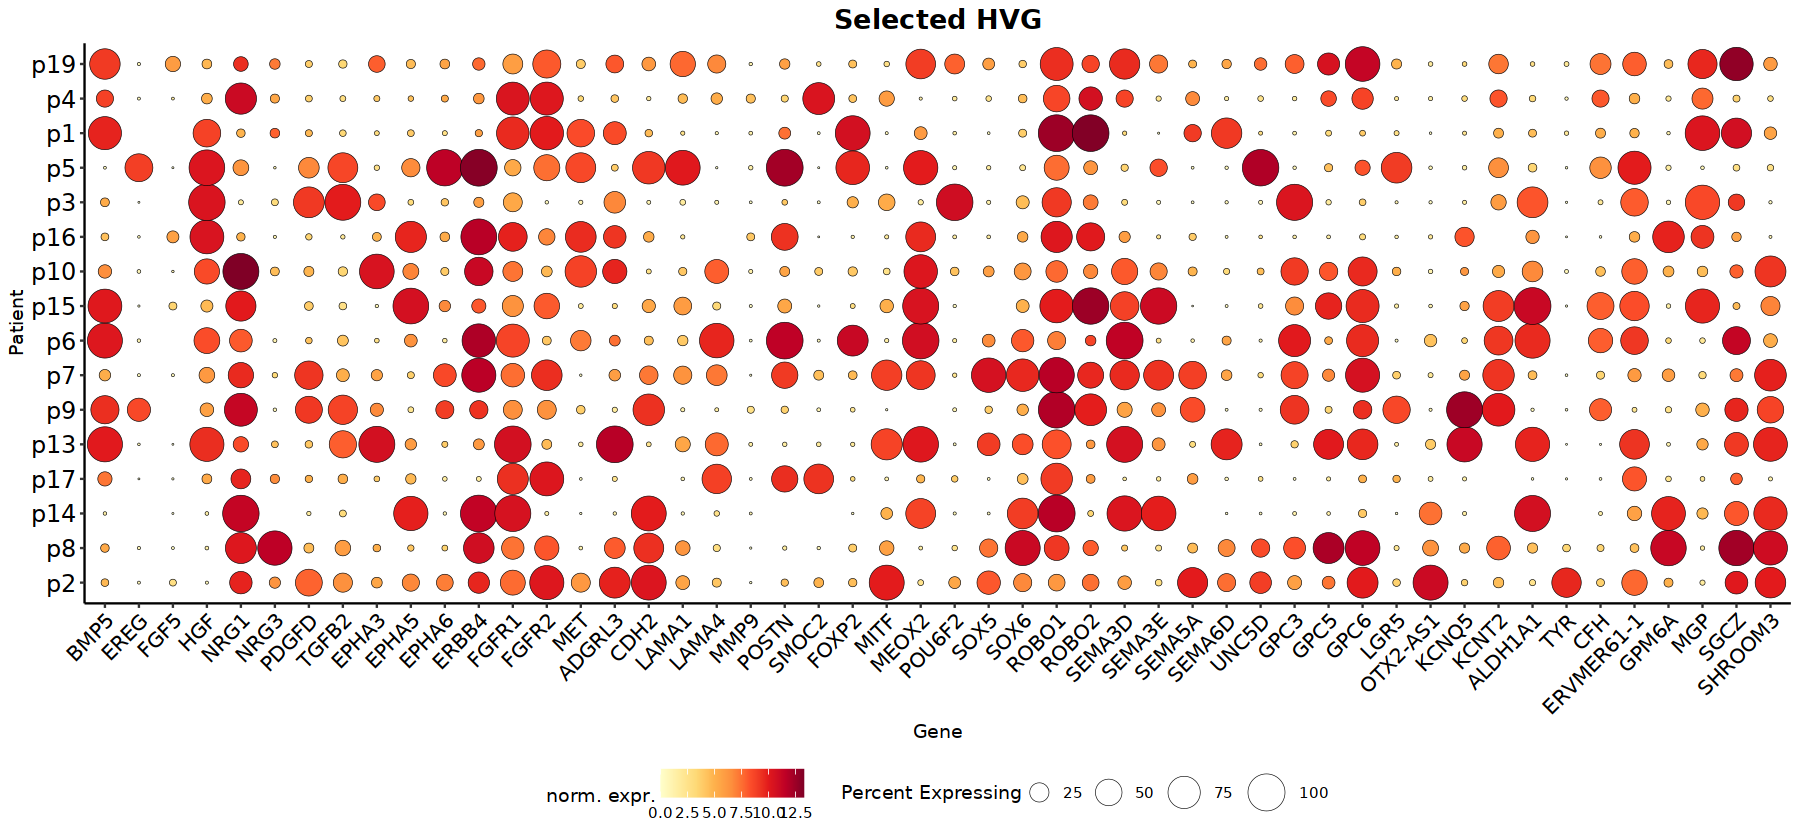

In [12]:
options(repr.plot.width = 15, repr.plot.height = 7)
dp <-  ggplot(expression_df, aes(x = Patient, y = Gene)) +
  geom_point(aes(size =  ifelse(PercentExpressing > 0, PercentExpressing, NA), fill = Expression),shape = 21, color = "black", stroke = 0.2) +
  theme_classic() +
  scale_fill_gradientn(colors = pal_gradient, name = leg_name) +
  scale_size(
    breaks = c(25, 50, 75, 100),
    limits = c(0, 100), 
    range = c(0, 10) 
  ) +
  ggtitle("Selected HVG") + 
  theme(plot.title = element_text(hjust = 0.5, size = 16, face = "bold"),
        axis.text.x = element_text(angle = 45, hjust = 1, size = 12, color="black"),
        axis.text.y = element_text(size = 14,color="black"),
        legend.position = "bottom",               
        legend.direction = "horizontal",          
        legend.box = "horizontal") +
  labs(x = "Patient", y = "Gene", color = "Expression", size = "Percent Expressing") +
  coord_flip()
dp

In [13]:
ggsave(plot = dp, width = 15, height = 7, dpi = 300, 
       file = here::here(glue::glue("{int}/{plt_dir}/4.1.2-selected_HVG.svg")))

Warning message:
“Removed 22 rows containing missing values (`geom_point()`).”


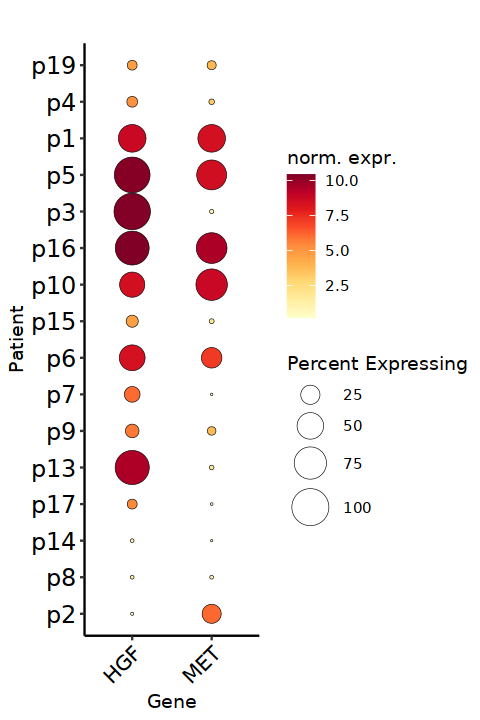

In [14]:
options(repr.plot.width = 4, repr.plot.height = 6)
dp <-  ggplot(expression_df[expression_df$Gene %in% c("HGF","MET"),], aes(x = Patient, y = Gene)) +
  geom_point(aes(size =  ifelse(PercentExpressing > 0, PercentExpressing, NA), fill = Expression),shape = 21, color = "black", stroke = 0.2) +
  theme_classic() +
  scale_fill_gradientn(colors = pal_gradient, name = leg_name) +
  scale_size(
    breaks = c(25, 50, 75, 100),
    limits = c(0, 100), 
    range = c(0, 10) 
  ) +
  ggtitle("") + 
  theme(plot.title = element_text(hjust = 0.5, size = 16, face = "bold"),
        axis.text.x = element_text(angle = 45, hjust = 1, size = 12, color="black"),
        axis.text.y = element_text(size = 14,color="black"),
        legend.position = "right",               
        legend.direction = "vertical",          
        legend.box = "vertical") +
  labs(x = "Patient", y = "Gene", color = "Expression", size = "Percent Expressing") +
  coord_flip()
dp

In [15]:
ggsave(plot = dp, width = 4, height = 6, dpi = 300, 
       file = here::here(glue::glue("{int}/{plt_dir}/4.1.2-HGF_MET.svg")))

Scale for fill is already present.
Adding another scale for fill, which will replace the existing scale.
Scale for fill is already present.
Adding another scale for fill, which will replace the existing scale.


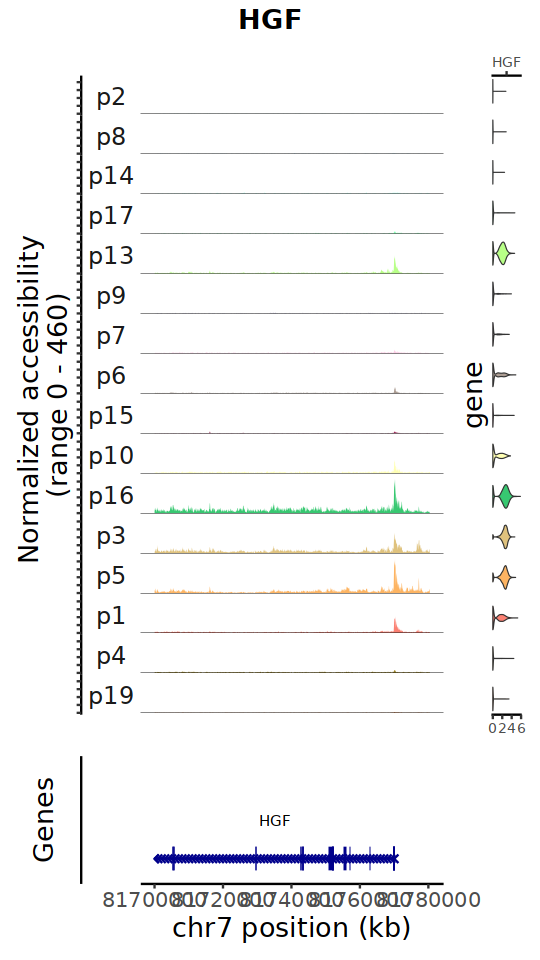

In [16]:
options(repr.plot.width = 4.5, repr.plot.height = 8, warn=-1,verbose = FALSE)
cp <- CoveragePlot(
  object = combined_obj,
  region = "chr7-81699010-81770438",
  features = "HGF",
  expression.assay = "RNA",
  assay="ATAC_unified",
  peaks = FALSE,
  extend.upstream = -1000,
  extend.downstream = 10000
) 

cp_st <- cp & 
  scale_fill_manual(breaks = names(colors_patients), values = colors_patients) & 
  patchwork::plot_annotation(title = "HGF") & 
  theme(
    plot.title = element_text(size = 16, face = "bold", hjust = 0.5),
    axis.title = element_text(size = 16),
    axis.text = element_text(size = 12),
    legend.title = element_text(size = 16), 
    legend.text = element_text(size = 14),
    strip.text = element_text(size = 14)
  )
cp_st

In [17]:
ggsave(plot = cp_st, width = 4.5, height = 8, dpi = 300, 
       file = here::here(glue::glue("{int}/{plt_dir}/4.1.1-HGF_peaks.pdf")))

Scale for fill is already present.
Adding another scale for fill, which will replace the existing scale.
Scale for fill is already present.
Adding another scale for fill, which will replace the existing scale.


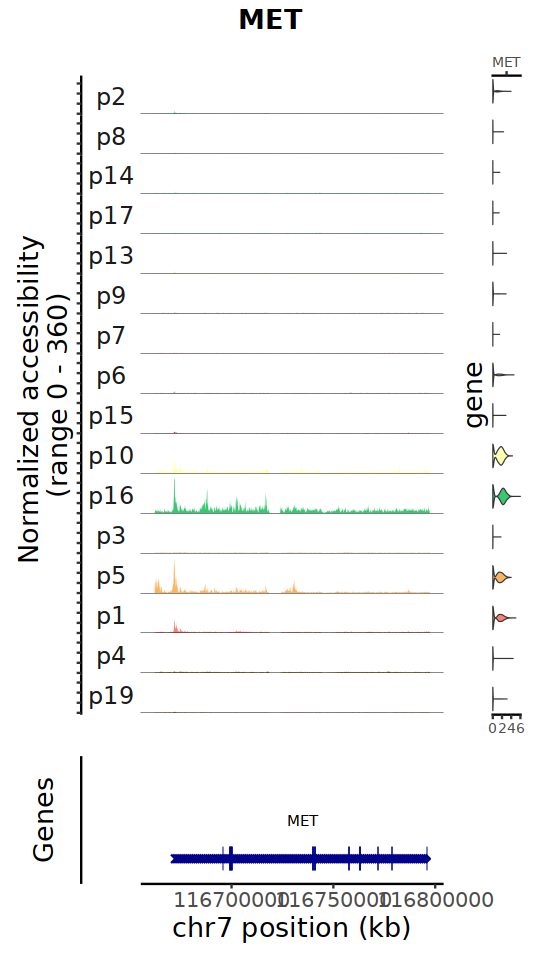

In [18]:
cp <- CoveragePlot(
  object = combined_obj,
  region = "chr7-116672196-116798377",
  features = "MET",
  expression.assay = "RNA",
  assay="ATAC_unified",
  peaks = FALSE,
  extend.upstream = 10000,
  extend.downstream = -1000
) 

cp_st <- cp & 
  scale_fill_manual(breaks = names(colors_patients), values = colors_patients) & 
  patchwork::plot_annotation(title = "MET") & 
  theme(
    plot.title = element_text(size = 16, face = "bold", hjust = 0.5),
    axis.title = element_text(size = 16),
    axis.text = element_text(size = 12),
    legend.title = element_text(size = 16), 
    legend.text = element_text(size = 14),
    strip.text = element_text(size = 14)
  )
cp_st

In [19]:
ggsave(plot = cp_st, width = 4.5, height = 8, dpi = 300, 
       file = here::here(glue::glue("{int}/{plt_dir}/4.1.1-MET_peaks.pdf")))

In [20]:
gene_functionality <- list(
    "Proliferative\nSignature" = c(
  "MKI67", "PCNA", "CCNB1", "CCNB2", "CDK2", "CDC20", "CDK1", "CDK4",
  "E2F1", "EZH2", "MYBL2", "FOXM1", "BIRC5", "AURKA", "AURKB", "KIF11",
  "KIF2C", "TOP2A", "TYMS", "RRM2", "PLK1", "NEK2", "CENPE", "CENPF",
  "NUSAP1", "KIF20A", "MCM2", "MCM4", "MCM6", "ORC6", "CDC45", "GINS2",
  "RPA2", "RFC4", "CLSPN", "CHEK1", "BUB1", "BUB1B", "CCNA2", "CCNE2",
  "G2E3", "PRC1", "GTSE1", "HMMR", "MCM10", "PSRC1", "TTK", "KNL1"))

In [21]:
logCPM <- edgeR::cpm(counts, log=TRUE)
mat1 <- t(scale(t(logCPM)))
mat1 <- mat1[unlist(gene_functionality, use.names = F),]

In [22]:
df_col <- data.frame(patients=colnames(mat1))
row.names(df_col) <- colnames(mat1)

In [23]:
df_row <- data.frame(
  functionality = rep(names(gene_functionality), times = sapply(gene_functionality, length)),
  genes = unlist(gene_functionality)
)
row.names(df_row) <- df_row$genes

In [24]:
gene_to_functionality <- unlist(lapply(names(gene_functionality), function(x) {
  setNames(rep(x, length(gene_functionality[[x]])), gene_functionality[[x]])
}))
functionality_factor <- factor(gene_to_functionality[rownames(mat1)], levels = names(gene_functionality))

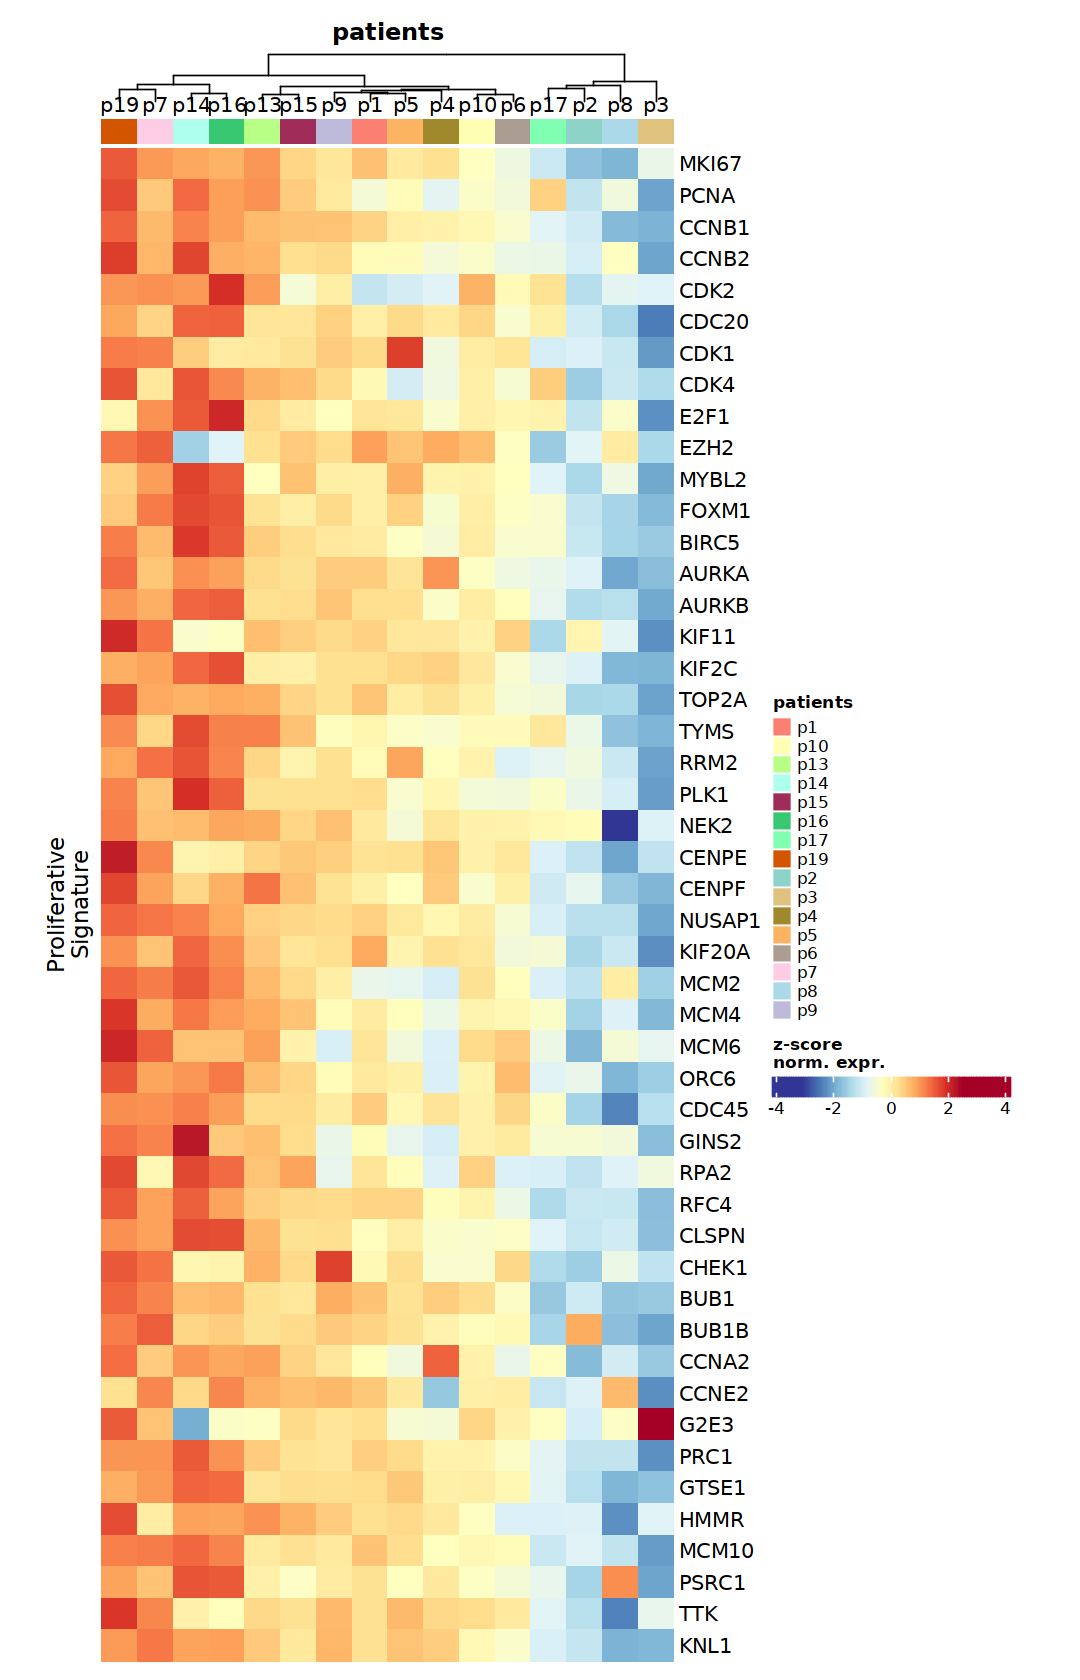

In [25]:
options(repr.plot.width = 9, repr.plot.height = 14, warn=-1,verbose = FALSE)
heatmap <- Heatmap(
  mat1,
  col = rev(c('#a50026','#d73027','#f46d43','#fdae61','#fee090','#ffffbf','#e0f3f8','#abd9e9','#74add1','#4575b4','#313695')),
  name = "z-score\nnorm. expr.",
  column_title = "patients",
  cluster_columns = TRUE,
  cluster_rows = FALSE,
  show_row_names = TRUE,
  show_column_names = FALSE,
  column_title_gp = gpar(fontsize = 14, fontface = "bold"),
  row_names_gp = gpar(fontsize = 12),
  top_annotation = HeatmapAnnotation(
      text = anno_text(colnames(mat1), rot = 0,
                      offset = unit(1, "npc"),just = "center", 
                      height=unit(0.3, "cm")), 
      df = df_col, 
      col = list(patients=unlist(colors_patients)),
      show_annotation_name = FALSE),
 heatmap_legend_param = list(legend_direction = "horizontal", 
                                legend_width = unit(5, "cm")),
    
  row_split = functionality_factor,
)

ht_drawn <- draw(heatmap, merge_legend = TRUE, column_dend_side = "bottom",
     heatmap_legend_side = "right",
    padding = unit(c(4, 10, 5,15), "mm"))

In [26]:
svg(here(glue("{int}/{plt_dir}/4.1.1-proliferation_signature.svg")),
   width = 9, height = 14)
draw(heatmap, merge_legend = TRUE, column_dend_side = "bottom",
     heatmap_legend_side = "right",
    padding = unit(c(4, 10, 5,15), "mm"))
dev.off()

png 
  2

In [27]:
sessionInfo()

R version 4.1.1 (2021-08-10)
Platform: x86_64-conda-linux-gnu (64-bit)
Running under: CentOS Linux 7 (Core)

Matrix products: default
BLAS/LAPACK: /home/groups/singlecell/isentis/conda_envs/ines_r4.1.1c/lib/libopenblasp-r0.3.24.so

locale:
 [1] LC_CTYPE=es_ES.UTF-8       LC_NUMERIC=C              
 [3] LC_TIME=es_ES.UTF-8        LC_COLLATE=es_ES.UTF-8    
 [5] LC_MONETARY=es_ES.UTF-8    LC_MESSAGES=es_ES.UTF-8   
 [7] LC_PAPER=es_ES.UTF-8       LC_NAME=C                 
 [9] LC_ADDRESS=C               LC_TELEPHONE=C            
[11] LC_MEASUREMENT=es_ES.UTF-8 LC_IDENTIFICATION=C       

attached base packages:
[1] grid      stats     graphics  grDevices utils     datasets  methods  
[8] base     

other attached packages:
 [1] glue_1.6.2            here_1.0.1            edgeR_3.36.0         
 [4] limma_3.50.3          ComplexHeatmap_2.10.0 lubridate_1.9.3      
 [7] forcats_1.0.0         stringr_1.5.0         dplyr_1.1.3          
[10] purrr_1.0.2           readr_2.1.4           tidyr